<a href="https://colab.research.google.com/github/Nafimunnisa/nafimunnisa-2026/blob/main/CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!nvidia-smi

Tue Nov  3 04:28:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
HOME = os.getcwd()
print(HOME)

/content


In [3]:
%pip install -q "ultralytics>=8.4.0" supervision roboflow

# prevent ultralytics from tracking your activity
!yolo settings sync=False
import ultralytics
ultralytics.checks()

Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.3/112.6 GB disk)


In [18]:
!yolo task=detect mode=predict model=yolo26m.pt source=/content/image.png save=True verbose=False

Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused): 130 layers, 20,411,132 parameters, 0 gradients, 68.4 GFLOPs
Results saved to /content/runs/detect/predict
💡 Learn more at https://docs.ultralytics.com/modes/predict


In [19]:
!ls -la {HOME}/runs/detect/predict/

total 100
drwxr-xr-x 2 root root  4096 Nov  3 05:06 .
drwxr-xr-x 3 root root  4096 Nov  3 05:06 ..
-rw-r--r-- 1 root root 91243 Nov  3 05:06 image.jpg


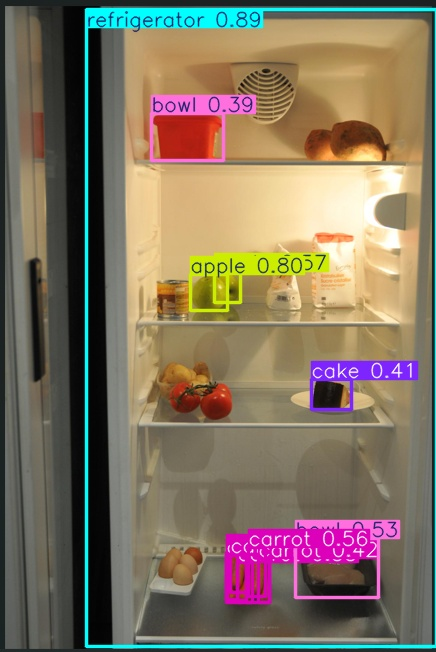

In [20]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/detect/predict/image.jpg', width=600)

In [21]:
!yolo task=detect mode=predict model=yolo26m.pt source=/content/Parking.png save=True verbose=False

Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused): 130 layers, 20,411,132 parameters, 0 gradients, 68.4 GFLOPs
Results saved to /content/runs/detect/predict-2
💡 Learn more at https://docs.ultralytics.com/modes/predict


In [22]:
!ls -la {HOME}/runs/detect/predict/

total 100
drwxr-xr-x 2 root root  4096 Nov  3 05:06 .
drwxr-xr-x 4 root root  4096 Nov  3 05:18 ..
-rw-r--r-- 1 root root 91243 Nov  3 05:06 image.jpg


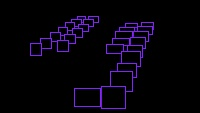

In [29]:
from IPython.display import Image as IPyImage

# YOLO converts png predictions to jpg format when saving
IPyImage(filename=f'{HOME}/runs/detect/predict-2/Parking.jpg', width=600)

In [30]:
!pip install -q -U ultralytics yt-dlp

In [31]:
!pip install -q -U ultralytics yt-dlp

import subprocess
import glob
from ultralytics import YOLO
from IPython.display import Video, display

# 1. YouTube URL
url = "https://www.youtube.com/watch?v=nUVnyFBCfl4"

# 2. Download first 10 seconds
subprocess.run([
    "yt-dlp",
    "--download-sections", "*00:00:00-00:00:30",
    "-f", "bv*[height<=720]+ba/b[height<=720]",
    "--merge-output-format", "mp4",
    "-o", "/content/video.mp4",
    url
], check=True)

# 3. Load YOLOv26m
model = YOLO("yolo26m.pt")

# 4. Detect ALL objects
model.predict(
    source="/content/video.mp4",
    conf=0.25,
    imgsz=640,
    save=True,
    project="/content/runs/detect",
    name="all_objects",
    exist_ok=True,
    verbose=False
)

# 5. Find output video
files = glob.glob("/content/runs/detect/all_objects/*.mp4")
files += glob.glob("/content/runs/detect/all_objects/*.avi")

# 6. Convert output to MP4
subprocess.run([
    "ffmpeg", "-y", "-loglevel", "error",
    "-i", files[0],
    "-c:v", "libx264",
    "-pix_fmt", "yuv420p",
    "/content/detected_10sec.mp4"
], check=True)

# 7. Display video
display(Video("/content/detected_10sec.mp4", embed=True, width=800))


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

Results saved to /content/runs/detect/all_objects


In [2]:
!pip install -q -U ultralytics opencv-python

import cv2
import numpy as np
import base64
from ultralytics import YOLO
from google.colab.output import eval_js
from google.colab import output
from IPython.display import display, Javascript

# 1. Load YOLOv26m model
model = YOLO("yolo26m.pt")

# 2. Start laptop webcam in browser
display(Javascript("""
window.yoloStop = false;

window.startCamera = async function() {
    const old = document.getElementById('yolo-camera-container');
    if (old) old.remove();

    const container = document.createElement('div');
    container.id = 'yolo-camera-container';

    const video = document.createElement('video');
    video.id = 'yolo-webcam';
    video.autoplay = true;
    video.playsInline = true;
    video.muted = true;
    video.style.width = '640px';

    const canvas = document.createElement('canvas');
    canvas.id = 'yolo-output';
    canvas.width = 640;
    canvas.height = 480;
    canvas.style.width = '640px';

    const button = document.createElement('button');
    button.innerText = 'Stop Camera';
    button.onclick = () => {
        window.yoloStop = true;
        if (video.srcObject) {
            video.srcObject.getTracks().forEach(t => t.stop());
        }
    };

    container.appendChild(video);
    container.appendChild(canvas);
    container.appendChild(button);
    document.body.appendChild(container);

    const stream = await navigator.mediaDevices.getUserMedia({
        video: {width: 640, height: 480},
        audio: false
    });

    video.srcObject = stream;
    await video.play();
    return true;
};

window.captureFrame = function() {
    if (window.yoloStop) return null;

    const video = document.getElementById('yolo-webcam');
    const canvas = document.createElement('canvas');

    canvas.width = 640;
    canvas.height = 480;

    const ctx = canvas.getContext('2d');
    ctx.drawImage(video, 0, 0, 640, 480);

    return canvas.toDataURL('image/jpeg', 0.7);
};

window.showDetection = function(data) {
    const canvas = document.getElementById('yolo-output');
    if (!canvas) return;

    const ctx = canvas.getContext('2d');
    const img = new Image();

    img.onload = () => {
        ctx.drawImage(img, 0, 0, 640, 480);
    };

    img.src = data;
};
"""))

# 3. Activate camera
eval_js("startCamera()")

print("Webcam started. Detecting all objects...")

# 4. Continuous detection
while True:
    frame_data = eval_js("captureFrame()")

    if frame_data is None:
        print("Camera stopped.")
        break

    # Decode webcam frame
    encoded = frame_data.split(",")[1]
    image_bytes = base64.b64decode(encoded)

    frame = cv2.imdecode(
        np.frombuffer(image_bytes, np.uint8),
        cv2.IMREAD_COLOR
    )

    # YOLO detection - ALL objects
    results = model.predict(
        frame,
        conf=0.25,
        imgsz=640,
        verbose=False
    )

    # Draw bounding boxes and labels
    annotated = results[0].plot()

    # Encode processed frame
    _, buffer = cv2.imencode(".jpg", annotated)
    output_data = base64.b64encode(buffer).decode("utf-8")

    # Display in Colab
    eval_js(
        "showDetection('data:image/jpeg;base64,"
        + output_data + "')"
    )


<IPython.core.display.Javascript object>

Webcam started. Detecting all objects...
Camera stopped.


In [3]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="z0U4nO8hrNQEXnGxj6rK")
project = rf.workspace("karel-cornelis-q2qqg").project("aicook-lcv4d")
version = project.version(4)
dataset = version.download("yolo26")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 128.3 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to aicook-4 in yolo26:: 100%|██████████| 6112/6112 [00:01<00:00, 4208.93it/s]
